# Data discovery and exploration of the Text2Hazard dataset

This notebook contains the data discovery and exploration before building the LLM extraction pipeline.

I use:
- the cleaned Markdown documents for text-based statistics;
- a manually reviewed Excel metadata table for document type and language information;
- the original PDF filenames only as a reference check.

The ZIP file is only read, so the original data stays unchanged.


## 1. Import the libraries

I only use common Python libraries, pandas, and matplotlib.


In [1]:
from pathlib import Path
from difflib import SequenceMatcher
import re
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

# Find the project folder
PROJECT_FOLDER = Path.cwd()

# The project may be run from the project folder or from a notebook subfolder.
candidate_folders = [
    PROJECT_FOLDER,
    PROJECT_FOLDER.parent,
]

for folder in candidate_folders:
    if (folder / "data/text_2_data.zip").exists() or (folder / "text_2_data.zip").exists():
        PROJECT_FOLDER = folder
        break

# Find the ZIP file
if (PROJECT_FOLDER / "data/text_2_data.zip").exists():
    ZIP_PATH = PROJECT_FOLDER / "data/text_2_data.zip"
else:
    ZIP_PATH = PROJECT_FOLDER / "text_2_data.zip"

# Find the manually reviewed metadata Excel file
metadata_candidates = [
    PROJECT_FOLDER / "data/text2data_document_metadata.xlsx",
    PROJECT_FOLDER / "text2data_document_metadata.xlsx",
]

METADATA_PATH = next(
    (path for path in metadata_candidates if path.exists()),
    metadata_candidates[0]
)

OUTPUT_FOLDER = PROJECT_FOLDER / "outputs"
FIGURE_FOLDER = OUTPUT_FOLDER / "figures"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
MAIN_COLOR = "#3274A1"

print(f"ZIP: {ZIP_PATH}")
print(f"Metadata: {METADATA_PATH}")


ZIP: C:\Users\onssr\Desktop\AIHWS\text2hazard_project\data\text_2_data.zip
Metadata: C:\Users\onssr\Desktop\AIHWS\text2hazard_project\data\text2data_document_metadata.xlsx


## 2. Helper functions

The helper functions below are only used for text-based exploration.


In [2]:
def count_words(text):
    # Count words made of letters
    pattern = r"\b[^\W\d_]+(?:['’\-][^\W\d_]+)*\b"
    return len(re.findall(pattern, text, flags=re.UNICODE))


def find_hazard_mentions(text):
    # One document can mention several hazards.
    # These are only keyword mentions, not ground-truth hazard labels.
    text = text.lower()

    keywords = {
        "Flood": ["flood", "flooding", "flash flood", "hochwasser"],
        "Storm": ["storm", "lightning", "cyclone", "tempest"],
        "Heat": ["heatwave", "heat wave", "extreme heat"],
        "Drought/low water": ["drought", "low water", "niedrigwasser"],
        "Wildfire": ["wildfire", "forest fire", "incendi"],
        "Cold/snow": ["freezing", "snowstorm", "cold wave", "snow"],
    }

    found = [
        hazard for hazard, words in keywords.items()
        if any(word in text for word in words)
    ]

    return found if found else ["Uncertain"]


def simple_title(filename):
    # Remove the author/year part before comparing titles
    title = Path(filename).stem.lower().removesuffix("_cleaned")
    title = re.sub(r"^.*?\b(?:19|20)\d{2}\b\s*-?\s*", "", title)
    return " ".join(re.findall(r"\w+", title))


def cleaned_document_name(filename):
    # Match the cleaned Markdown filenames to the document_name column in Excel
    return re.sub(r"_cleaned\.md$", "", Path(filename).name, flags=re.I)


## 3. Read the cleaned text and metadata

I calculate text statistics from the cleaned Markdown files, then merge them with the manually reviewed Excel table.

The Excel table is treated as the source for:
- document type;
- cleaned-text language;
- original source language.


In [3]:
# Read the manually reviewed metadata
metadata = pd.read_excel(METADATA_PATH)

expected_columns = {
    "document_name",
    "document_type",
    "cleaned_language",
    "original_source_language",
}

missing_columns = expected_columns - set(metadata.columns)
if missing_columns:
    raise ValueError(f"Missing metadata columns: {sorted(missing_columns)}")

metadata = metadata[list(expected_columns)].copy()

rows = []

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    files = [item for item in archive.infolist() if not item.is_dir()]
    pdf_files = [item for item in files if item.filename.lower().endswith(".pdf")]
    md_files = [item for item in files if item.filename.lower().endswith(".md")]

    for item in md_files:
        text = archive.read(item).decode("utf-8-sig", errors="replace")
        filename = Path(item.filename).name

        rows.append({
            "filename": filename,
            "document_name": cleaned_document_name(filename),
            "text": text,
            "words": count_words(text),
            "characters": len(text),
            "hazard_keyword_mentions": find_hazard_mentions(text),
            "broken_characters": text.count("�"),
            "replacement_char_ratio": text.count("�") / max(len(text), 1),
        })

text_stats = pd.DataFrame(rows)

# Merge text statistics with manually reviewed metadata
df = text_stats.merge(
    metadata,
    on="document_name",
    how="left",
    validate="one_to_one",
)

print(f"{len(pdf_files)} PDFs found.")
print(f"{len(md_files)} cleaned Markdown files found.")
print(f"{len(metadata)} metadata rows found.")
print(f"{len(df)} merged documents.")

# Check whether any cleaned document failed to match the metadata table
unmatched = df[df["document_type"].isna()]

if len(unmatched) == 0:
    print("All cleaned documents matched the metadata table.")
else:
    print(f"WARNING: {len(unmatched)} cleaned documents did not match the metadata table.")
    display(unmatched[["filename", "document_name"]])

df.head(3)


77 PDFs found.
76 cleaned Markdown files found.
76 metadata rows found.
76 merged documents.
All cleaned documents matched the metadata table.


,filename,document_name,text,words,characters,hazard_keyword_mentions,broken_characters,replacement_char_ratio,document_type,cleaned_language,original_source_language
0,ABC 2024 - Traffic jams and flight delays due ...,ABC 2024 - Traffic jams and flight delays due ...,# ABC 2024 - Traffic jams and flight delays du...,706,4481,"[Flood, Storm]",0,0.0,News / media,English,English
1,AEMET 2024 - ESTUDIO SOBRE LA SITUACIÓN DE LLU...,AEMET 2024 - ESTUDIO SOBRE LA SITUACIÓN DE LLU...,# AEMET 2024 - ESTUDIO SOBRE LA SITUACIÓN DE L...,10477,66018,"[Flood, Storm]",0,0.0,Institutional / technical report,English,Spanish
2,AFP 2022 - The_Vibes_Valencia Airport in Madri...,AFP 2022 - The_Vibes_Valencia Airport in Madri...,# AFP 2022 - The\_Vibes\_Valencia Airport in M...,327,2258,"[Flood, Storm]",0,0.0,News / media,English,English


## 4. Missing cleaned documents

I compare the original PDF filenames with the cleaned Markdown filenames to check whether every source document has a cleaned version.


In [4]:
pdf_names = {
    Path(item.filename).stem.lower(): Path(item.filename).name
    for item in pdf_files
}

cleaned_names = {
    re.sub(r"_cleaned$", "", Path(item.filename).stem.lower())
    for item in md_files
}

missing_cleaned = [
    original_name
    for stem, original_name in pdf_names.items()
    if stem not in cleaned_names
]

print(f"PDFs: {len(pdf_files)}")
print(f"Cleaned Markdown files: {len(md_files)}")
print(f"PDFs without a matched cleaned Markdown file: {len(missing_cleaned)}")

if missing_cleaned:
    display(pd.DataFrame({"PDF without cleaned version": missing_cleaned}))


PDFs: 77
Cleaned Markdown files: 76
PDFs without a matched cleaned Markdown file: 1


,PDF without cleaned version
0,Papatolios 2021 - Belgium-Germany_ estimated c...


## 5. Possible duplicates

I compare simplified filenames/titles to flag documents that may describe the same article or source under slightly different filenames. This is only a screening step, so any flagged pair still needs to be checked manually.


In [5]:
possible_duplicates = []

for first in range(len(df)):
    for second in range(first + 1, len(df)):
        title_1 = simple_title(df.iloc[first]["filename"])
        title_2 = simple_title(df.iloc[second]["filename"])

        similarity = SequenceMatcher(None, title_1, title_2).ratio()

        if similarity >= 0.88:
            possible_duplicates.append({
                "document_1": df.iloc[first]["document_name"],
                "document_2": df.iloc[second]["document_name"],
                "title_similarity": round(similarity, 3),
            })

possible_duplicates = pd.DataFrame(possible_duplicates)

if len(possible_duplicates) == 0:
    print("No strong filename/title duplicate candidates found.")
else:
    display(
        possible_duplicates.sort_values(
            "title_similarity",
            ascending=False
        )
    )


,document_1,document_2,title_similarity
0,The Guardian 2015 - Storm Desmond damage acros...,Treanor 2015 - Storm Desmond damage across Cum...,0.908


I checked the flagged pair manually against the original documents and confirmed that it is a duplicate.


## 6. Dataset overview

I first check how many cleaned documents are available and how different their lengths are. Large differences in length are relevant for the later LLM workflow because longer documents may need chunking.


In [6]:
overview = pd.DataFrame({
    "Result": [
        len(df),
        int(df["words"].sum()),
        int(df["words"].min()),
        int(df["words"].median()),
        int(df["words"].max()),
        df["document_type"].nunique(),
        df["original_source_language"].nunique(),
    ]
}, index=[
    "Cleaned documents",
    "Total words",
    "Minimum words/document",
    "Median words/document",
    "Maximum words/document",
    "Document types",
    "Original source languages",
])

display(overview)


,Result
Cleaned documents,76
Total words,262721
Minimum words/document,157
Median words/document,1260
Maximum words/document,25888
Document types,3
Original source languages,6


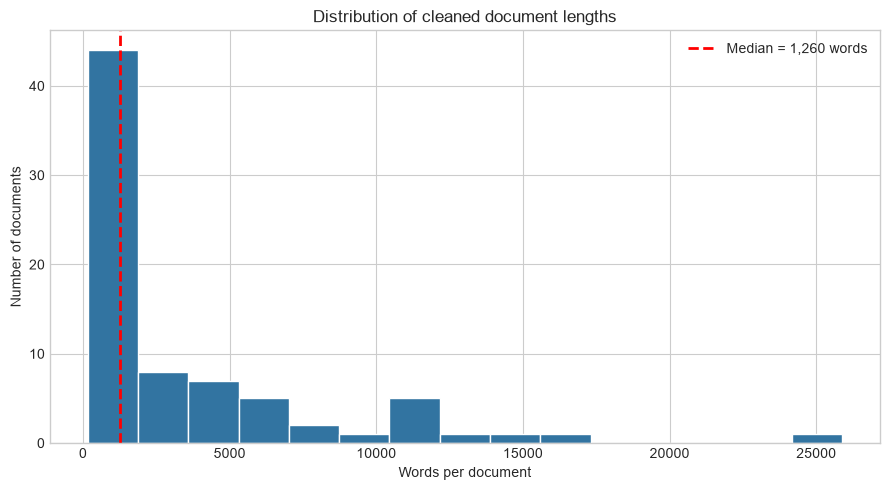

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df["words"], bins=15, color=MAIN_COLOR, edgecolor="white")
ax.axvline(
    df["words"].median(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median = {int(df['words'].median()):,} words",
)

ax.set(
    title="Distribution of cleaned document lengths",
    xlabel="Words per document",
    ylabel="Number of documents",
)
ax.legend()

fig.tight_layout()
fig.savefig(FIGURE_FOLDER / "document_length_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


The distribution is strongly right-skewed: most documents are relatively short, while a few are much longer. This suggests that the later extraction pipeline should not process every document in exactly the same way. Longer documents will probably need chunking or section-based processing.


## 7. Document types

The source-type categories come directly from the manually reviewed metadata table.

For the current exploration, I use three broad groups:
- **News / media**
- **Scientific papers**
- **Institutional / technical reports**

These broad groups are mainly used to describe the heterogeneity of the corpus.


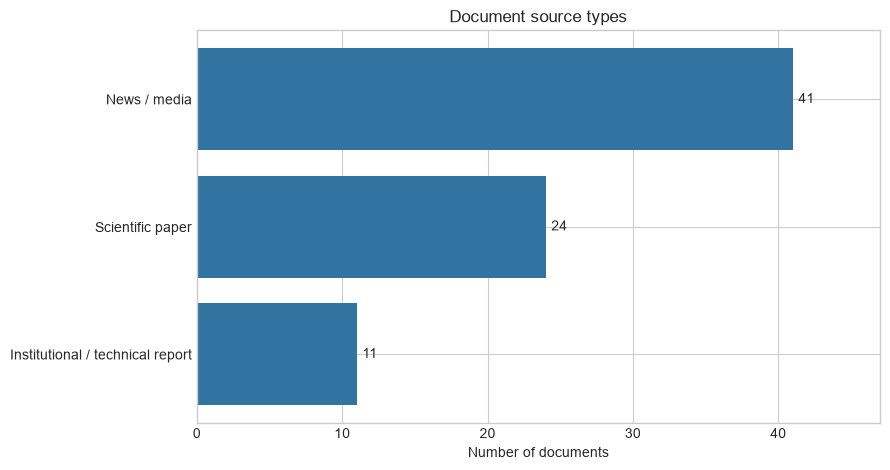

,Documents
document_type,
News / media,41
Scientific paper,24
Institutional / technical report,11


In [8]:
type_order = [
    "News / media",
    "Scientific paper",
    "Institutional / technical report",
]

type_counts = (
    df["document_type"]
    .value_counts()
    .reindex(type_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(type_counts.index, type_counts.values, color=MAIN_COLOR)
ax.bar_label(bars, padding=4)

ax.set(
    title="Document source types",
    xlabel="Number of documents",
    ylabel="",
)
ax.invert_yaxis()
ax.set_xlim(0, type_counts.max() + 6)

fig.tight_layout()
fig.savefig(FIGURE_FOLDER / "document_types.png", dpi=300, bbox_inches="tight")
plt.show()

display(type_counts.rename("Documents").to_frame())


### Document length by source type

The overall median does not show how document length varies between source types. I therefore compare the word-count distribution for the three broad source groups.


,count,min,median,mean,max
document_type,,,,,
Institutional / technical report,11,484,1922.0,5581.0,15880
News / media,41,157,706.0,808.7,3635
Scientific paper,24,1457,5808.0,7007.3,25888


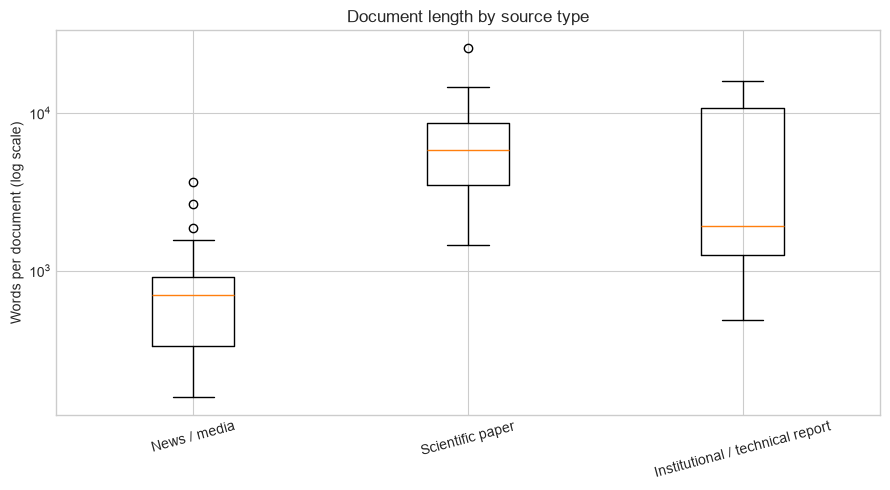

In [9]:
length_summary = (
    df.groupby("document_type")["words"]
    .agg(["count", "min", "median", "mean", "max"])
    .round(1)
)

display(length_summary)

fig, ax = plt.subplots(figsize=(9, 5))

plot_order = [t for t in type_order if t in df["document_type"].unique()]

data = [
    df.loc[df["document_type"] == document_type, "words"]
    for document_type in plot_order
]

ax.boxplot(data, tick_labels=plot_order, showfliers=True)
ax.set_yscale("log")
ax.set(
    title="Document length by source type",
    ylabel="Words per document (log scale)",
    xlabel="",
)
ax.tick_params(axis="x", rotation=15)

fig.tight_layout()
fig.savefig(FIGURE_FOLDER / "document_length_by_type.png", dpi=300, bbox_inches="tight")
plt.show()


### Potential document-length outliers

To describe unusually long or short documents, I use the 1.5 × IQR rule. Documents below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR` are flagged as potential statistical outliers. This is only an exploratory check and does not remove or change any documents.


In [10]:
q1 = df["words"].quantile(0.25)
q3 = df["words"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

potential_length_outliers = (
    df.loc[
        (df["words"] < lower_fence) | (df["words"] > upper_fence),
        ["document_name", "document_type", "words"],
    ]
    .sort_values("words")
    .reset_index(drop=True)
)

print(f"Q1: {q1:,.2f} words")
print(f"Q3: {q3:,.2f} words")
print(f"IQR: {iqr:,.2f} words")
print(f"Lower fence: {lower_fence:,.2f} words")
print(f"Upper fence: {upper_fence:,.2f} words")
print(f"Potential outliers: {len(potential_length_outliers)}")

display(potential_length_outliers)


Q1: 568.75 words
Q3: 4,683.75 words
IQR: 4,115.00 words
Lower fence: -5,603.75 words
Upper fence: 10,856.25 words
Potential outliers: 8


,document_name,document_type,words
0,IPCC 2018 - Working Group 2 Cross-chapter case...,Institutional / technical report,10907
1,Fekete 2025 - Cascading impact chains and reco...,Scientific paper,11444
2,McGregor 2007 - The social impacts of heat waves,Scientific paper,11639
3,Mohr 2022 - A multi-disciplinary analysis of t...,Scientific paper,11690
4,Eurelectric 2006 - Impacts of Severe Storms on...,Institutional / technical report,13074
5,Deidda 2025 - Is Europe's transport infrastruc...,Scientific paper,14629
6,Hladny 2004 - August_2002_catastrophic_flood_i...,Institutional / technical report,15880
7,Tapsell 2010 - Social vulnerability to natural...,Scientific paper,25888


Eight documents are above the upper fence. Hladny (2004) and Tapsell (2010) also occur in the candidate evaluation sample. Here, the outlier flag is descriptive only. I will check how to prepare these documents later in the data-preparation stage.


## 8. Hazard keyword mentions

As a rough overview, I count whether each cleaned document contains keywords related to different hazards. Each category is counted at most once per document, and a document can contain several categories, so the counts overlap.

These are document-level keyword-presence counts and are **not** manually verified hazard labels.


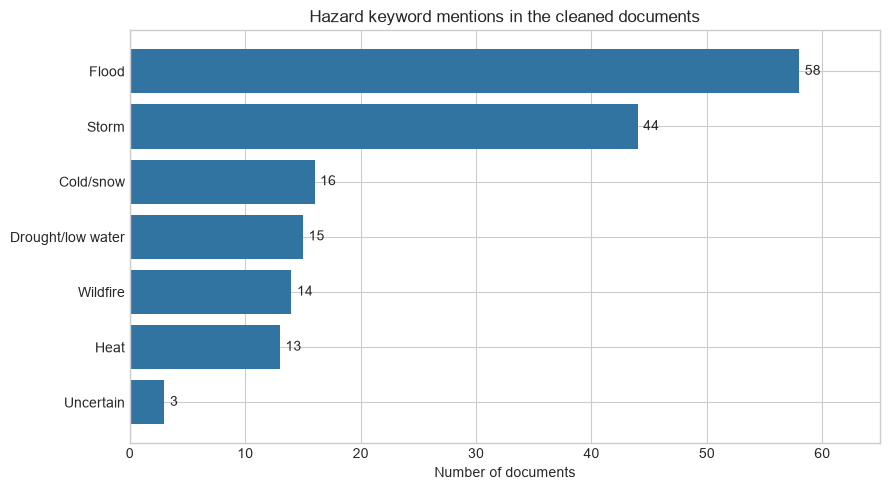

In [11]:
hazard_counts = (
    df.explode("hazard_keyword_mentions")["hazard_keyword_mentions"]
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(hazard_counts.index, hazard_counts.values, color=MAIN_COLOR)
ax.bar_label(bars, padding=4)

ax.set(
    title="Hazard keyword mentions in the cleaned documents",
    xlabel="Number of documents",
    ylabel="",
)
ax.set_xlim(0, hazard_counts.max() + 7)

fig.tight_layout()
fig.savefig(FIGURE_FOLDER / "hazard_mentions.png", dpi=300, bbox_inches="tight")
plt.show()


Flood- and storm-related keywords appear often in the cleaned corpus. I do not use these counts as ground-truth hazard categories because a document can mention a hazard without being mainly about that hazard.


## 9. Language and text-quality checks

Language information comes from the manually reviewed metadata table.

I distinguish between:
- **cleaned language:** the language of the Markdown text used by the LLM pipeline;
- **original source language:** the language of the original document/source.

I also check the Unicode replacement character (`�`) as a simple indication of possible text-conversion problems.


Cleaned text language


,Documents
cleaned_language,
English,76



Original source language


,Documents
original_source_language,
English,63
German,8
French,2
Spanish,1
Italian,1
Dutch,1


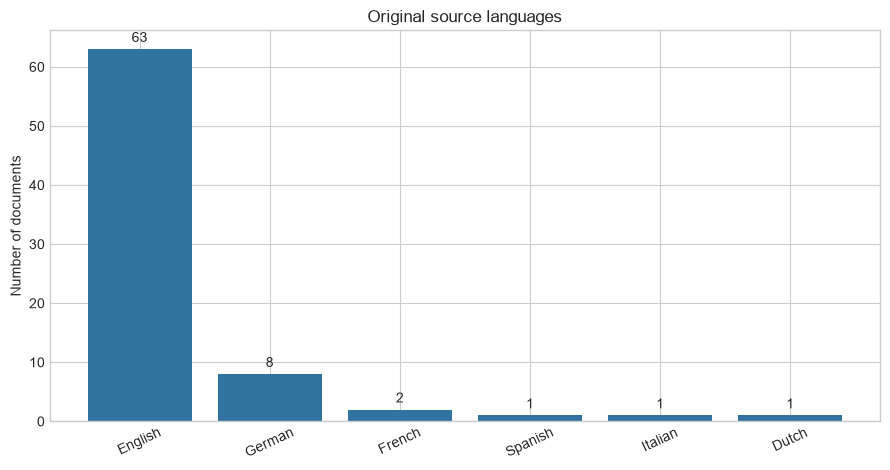


18 replacement characters across 8 documents


,document_name,broken_characters,replacement_char_ratio
43,Maioni 2023 - A catastrophic event: the Vaia S...,5,0.000939
39,Lavenir 2021 - À la recherche d'une jeune fill...,3,0.003272
25,Grieshaber 2026 - It's so hot in Germany the A...,2,0.000203
3,Ambrose 2026 - Great Britain’s grid operator w...,2,0.000441
61,Sunbird 2026 - Europe's Heatwave Is a Real-Tim...,2,0.001649
44,Manhold 2021 - Repair works after flood disast...,2,0.000355
6,Berglund 2018 - Drought blamed for high power ...,1,0.000304
63,Tempest 2019 - Sweden could be heading for a n...,1,0.000586


In [12]:
print("Cleaned text language")
display(
    df["cleaned_language"]
    .value_counts()
    .rename("Documents")
    .to_frame()
)

print("\nOriginal source language")
source_language_counts = (
    df["original_source_language"]
    .value_counts()
)

display(source_language_counts.rename("Documents").to_frame())

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(
    source_language_counts.index,
    source_language_counts.values,
    color=MAIN_COLOR,
)
ax.bar_label(bars, padding=3)

ax.set(
    title="Original source languages",
    xlabel="",
    ylabel="Number of documents",
)
ax.tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(FIGURE_FOLDER / "original_source_languages.png", dpi=300, bbox_inches="tight")
plt.show()

broken_total = int(df["broken_characters"].sum())
broken_docs = int((df["broken_characters"] > 0).sum())

print(f"\n{broken_total} replacement characters across {broken_docs} documents")

if broken_docs > 0:
    display(
        df.loc[
            df["broken_characters"] > 0,
            ["document_name", "broken_characters", "replacement_char_ratio"]
        ].sort_values("broken_characters", ascending=False)
    )


## 10. First conclusions

From this first exploration:

- The cleaned corpus is linked to a manually reviewed metadata table containing document type and language information.
- Document lengths vary strongly, and the 1.5 × IQR rule flags eight potential length outliers.
- The corpus contains three broad source groups: news/media, scientific papers, and institutional/technical reports.
- The cleaned texts are mainly in English, while the original sources include several languages.
- Flood- and storm-related keywords appear frequently, but the keyword counts are not ground-truth hazard labels.
- Text-conversion problems can be screened using replacement characters and checked manually where needed.
- One flagged pair was checked manually and confirmed as a duplicate. How the duplicate is handled will be decided during data preparation.
- The PDF `Papatolios 2021 - Belgium-Germany_ estimated costs for flood damage repairs reach billions.pdf` has no matched cleaned Markdown file. This also needs to be handled during data preparation.
